# Training a detector

<!-- markdownlint-disable MD033-->
<div class="page-subtitle">
A practical, end-to-end workflow for training an object detector
</div>
<!-- markdownlint-enable MD033 -->

---

## 1. Motivation

This is the page where the concepts from earlier in the lesson, bounding boxes, confidence scores, architecture choice, become an actual trained model. The `geoai` package deliberately hides a substantial amount of boilerplate (the training loop, the learning-rate scheduler, checkpoint saving) behind a small set of parameters, so your job is to understand what those parameters control well enough to make good choices for your own project data later.

---

## 2. Core idea

`geoai.train_multiclass_detector()` runs the complete training pipeline in one call: it loads images and {term}`COCO <COCO Format>` annotations, builds the detection model you specify, runs the training loop with a learning-rate schedule, and saves the best checkpoint based on validation performance. You provide the data locations and a handful of hyperparameters; the function returns the path to the saved model.

---

## 3. Workflow

### A. Prepare the dataset

The following cells reproduce the setup from the previous page so that the key training variables are explicit.

```{admonition} Running on a Mac with Apple silicon
:class: note
On a Mac with an M-series chip, PyTorch uses the GPU through its MPS backend. One operation the detector needs, non-maximum suppression (`torchvision::nms`), is not yet available on MPS, so without the setting below the code stops with a `NotImplementedError`. Setting `PYTORCH_ENABLE_MPS_FALLBACK=1` runs just that operation on the CPU while everything else stays on the GPU. It must be set before PyTorch is imported (here via `geoai`), so if you have already run the imports, restart the kernel first. On Windows, Linux or Google Colab the setting has no effect and you can leave it in place.
```

In [1]:
import os

# Apple silicon only: run operations missing on MPS on the CPU instead
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"

import geoai
from pathlib import Path

In [2]:
DATA_DIR = Path("data/raw")
DATA_DIR.mkdir(parents=True, exist_ok=True)

url = "https://data.source.coop/giuz/sds320/L06/data/NWPU-VHR-10.zip"

data_dir = geoai.download_file(url, output_path=str(DATA_DIR / Path(url).name))

splits = geoai.prepare_nwpu_vhr10(
    data_dir,
    val_split=0.2,
    seed=42,
)

The fixed seed helps make the split reproducible.

### B. Set the architecture information

In [ ]:
# Runtime: ~4 h (~1 h in Colab using T4 GPU)
# Hardware: Apple M3 Pro (18 GB RAM, MPS GPU acceleration)

output_dir = "nwpu_output"

model_path = geoai.train_multiclass_detector(
    images_dir=splits["images_dir"],
    annotations_path=splits["train_annotations"],
    output_dir=output_dir,
    model_name="fasterrcnn_resnet50_fpn_v2",
    class_names=splits["class_names"],
    num_channels=3,
    batch_size=4,
    num_epochs=10,
    learning_rate=0.005,
    val_split=0.1,
    seed=42,
    pretrained=True,
    verbose=True,
)

[W1012 16:27:14.841815000 MPSFallback.mm:34] Warning: The operator 'torchvision::nms' is not currently supported on the MPS backend and will fall back to run on the CPU. This may have performance implications. (function operator())


Several arguments deserve explicit attention.

| Argument | Explanation |
| --- | --- |
| `output_dir` | The output directory keeps checkpoints and training history separate from your raw data. This becomes particularly important in your own repository. |
| `model_name` | Selects the detector architecture. The baseline uses Faster R-CNN. You could later test another supported architecture, but change one major modelling decision at a time. |
| `class_names` | The class names need to correspond to the annotation category IDs expected by the workflow (`splits["class_names"]`). The list includes a background class at index 0. |
| `num_channels` | This tells the model to expect standard RGB imagery; you would change this if working with multispectral chips. |
| `batch_size` | The batch size controls how many training samples are processed together. Larger values usually require more accelerator memory. |
| `num_epochs` | An {term}`Epoch` is one full pass through the training data. Ten epochs provide a reasonable starting experiment for the benchmark workflow. More epochs are not automatically better: eventually the model may stop improving on unseen data or begin to {term}`Overfitting`. |
| `learning_rate` | The learning rate controls the size of parameter updates during optimisation. It is a {term}`Hyperparameter`: it is chosen by you rather than learned directly from the data. `0.005` with a step-based schedule is a reasonable default for this architecture. |
| `val_split` | This is an internal validation fraction used during training. Do not confuse it with the held-out validation/evaluation split created earlier by `prepare_nwpu_vhr10`. |
| `seed` | A fixed random seed supports reproducibility. It does not make every GPU operation perfectly deterministic, but it removes an avoidable source of variation. |
| `pretrained` | Initializes the backbone with ImageNet weights rather than random values, a form of {term}`transfer learning <Transfer Learning>` that generally speeds up training and improves results when your own labeled dataset is small. |

Note that `num_epochs`, `batch_size`, `learning_rate` and `val_split` are {term}`hyperparameters <Hyperparameter>` that can be adjusted to improve the model performance.

```{admonition} Two different val_split values, two different purposes
:class: warning
`prepare_nwpu_vhr10(..., val_split=0.2)` on the previous page created your held-out **evaluation** set, the one you will score the finished model against on the mAP page. `train_multiclass_detector(..., val_split=0.1)` here creates a separate **internal** validation split, carved out of the training images only, used to monitor training and choose the best {term}`checkpoint`. These two splits do not overlap, and confusing them is a common source of misleadingly optimistic evaluation results.
```

### C. Run training and check the output

The function returns `model_path`, a string path to the saved best checkpoint on disk. You can pass this path directly to the evaluation and inference functions on the next two pages, so keep it around.

```{admonition} CPU or GPU?
:class: info
Deep-learning training can be computationally demanding. A compatible {term}`GPU` can accelerate training substantially. In many Python environments, NVIDIA GPU acceleration is provided through {term}`CUDA`. Check your setup on [GPU vs. CPU](https://hendrikwulf.github.io/sds320-jb/book/setup/software/#e-optional-gpu-and-cuda-setup)
```

### D. Plot the training history

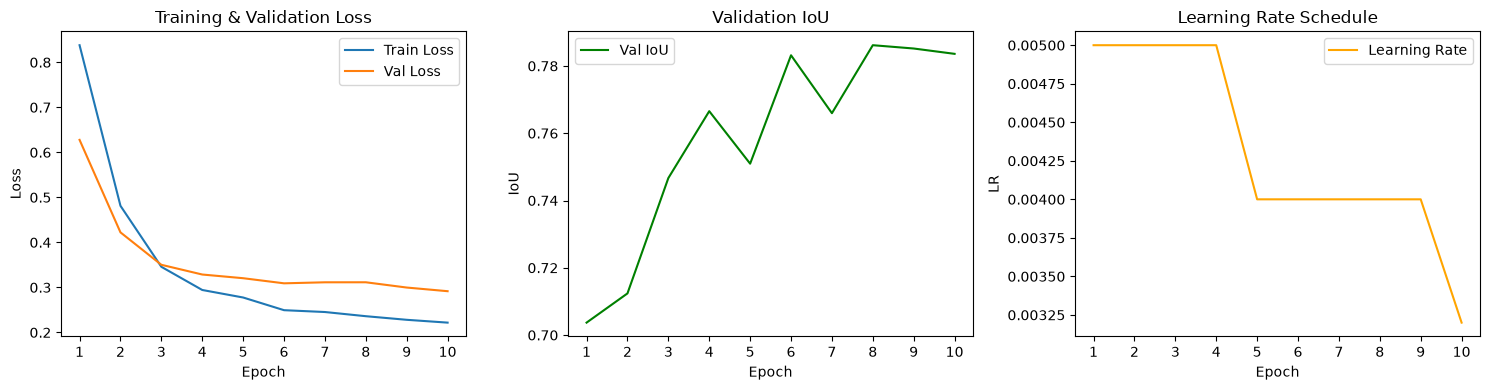

In [4]:
geoai.plot_detection_training_history(
    history_path=os.path.join(output_dir, "training_history.pth"),
)

This produces three panels: training loss (should decrease and level off in a healthy run), validation IoU (should generally increase as box localization improves, though some fluctuation between epochs is normal), and the learning-rate schedule (showing when the scheduler reduced the rate during training). Reviewing these before moving on tells you whether training actually worked before you invest time in evaluation and inference.

```{tip}
If training loss is not decreasing at all after a few epochs, double check your data first (revisit the visual annotation check from the previous page) before assuming the architecture or hyperparameters are the problem. A silent data issue is a far more common cause than a genuinely unsuitable model.
```

---

## 4. Python reactivation

`train_multiclass_detector()` is called entirely with keyword arguments (`images_dir=...`, `batch_size=4`, and so on) rather than positional ones. This is a common pattern for functions with many parameters: it makes each call self-documenting and lets you reorder or omit arguments that have sensible defaults, at the cost of a longer line of code. `os.path.join(output_dir, "training_history.pth")` builds a file path by joining pieces, the same idea behind {term}`Pathlib`, but using the older `os.path` module and plain strings instead of path objects.

---

## 5. Common pitfalls

- **Confusing the two `val_split` parameters**, as described above. Keep clear in your own notes which split is for final evaluation and which is for monitoring training.
- **Changing several hyperparameters at once when troubleshooting.** If a run performs poorly, change one parameter at a time so you can tell what actually mattered, the same principle from the architecture-comparison page.
- **Reusing `output_dir` across runs without noticing.** Overwriting a previous run's checkpoint and history file makes it hard to compare experiments later; use a distinct `output_dir` per configuration you want to keep.
- **Skipping the training-history plot.** A model can finish training without errors and still have failed to learn anything useful; the loss and validation IoU curves are your first check.

---

## 6. Mini task

Using the parameters above as a baseline, describe (in words, no need to actually retrain unless you have time) what you would expect to change if you set `num_epochs=3` instead of `10`, keeping everything else fixed. Would you expect training loss to be higher or lower than the 10-epoch run? What about validation IoU?

:::{dropdown} Sample solution
:class: note

With only 3 epochs, the model has fewer opportunities to update its weights, so training loss would likely still be relatively high and validation IoU relatively low compared to the 10-epoch run, similar to looking at the leftmost points on the training-history curves rather than the rightmost ones. This does not necessarily mean 3 epochs is "wrong": for a quick feasibility check on new project data, a short run is a reasonable first step before committing to a longer, more expensive training run.
:::

---

## 7. Key takeaways

- `train_multiclass_detector()` handles the full training pipeline: data loading, model construction, the training loop, and checkpoint saving.
- `model_name`, `class_names`, and `pretrained` set up the architecture; `num_epochs`, `batch_size`, `learning_rate`, `val_split`, and `seed` control how training proceeds.
- The `val_split` used here (internal validation during training) is separate from the `val_split` used when preparing the dataset (final evaluation set); keep the two distinct.
- Always check the training-history plot before moving on to evaluation; a smooth-looking training run is not proof the model learned anything useful.
- The returned `model_path` is what you will pass into evaluation and inference on the following pages.

### Further reading

- OpenGeoAI, ["Multi-Class Object Detection with NWPU-VHR-10"](https://opengeoai.org/examples/object_detection_nwpu/) — the full, runnable notebook this workflow is based on.
- OpenGeoAI, ["Train Object Detection Model"](https://opengeoai.org/examples/train_object_detection_model/) — a related `geoai` example using `train_MaskRCNN_model()` for a single-class detection task, useful if your project only needs to find one type of object rather than several.